# Assignment 2 — Parameter Identification Using POD-NN

## 1. Problem Formulation

The objective of this task is to identify the unknown physical parameters governing damage propagation in the U-bolt, using time-dependent measurements collected at a fixed spatial location.

A previously trained POD-NN surrogate model is employed to approximate the full-order solution:

$$
\widetilde{u}(x,t;\boldsymbol{\mu})
=
\sum_{k=1}^{N} a_k^{\mathrm{NN}}(t,\boldsymbol{\mu})\,\phi_k(x),
$$

where $N=50$ is the number of retained POD modes and $\boldsymbol{\mu}\in[0,1]^3$ is the normalized parameter vector.

Given sensor measurements $m_j$ at position $x_0=(0.5,3)$ and times $t_j$, the unknown parameters are estimated by solving

$$
\boldsymbol{\mu}^{*}
=
\underset{\boldsymbol{\mu}\in[0,1]^3}{\operatorname{argmin}}
\frac{1}{M}\sum_{j=1}^{M}
\left[
m_j-\widetilde{u}(x_0,t_j;\boldsymbol{\mu})
\right]^2.
$$

The identified normalized parameters are subsequently converted into physical quantities:

$$
D=10^{\mu_1},\qquad
r=10^{\mu_2+2},\qquad
\delta=\mu_3+1.
$$

The POD basis and neural network parameters remain fixed throughout the optimization. Only the three input parameters are estimated.

In [3]:
from pathlib import Path

import numpy as np
import torch
import support_functions as sf

# Paths and computational device
ARTIFACTS = Path("artifacts")
DEVICE = "cpu"

# Load POD basis and coefficient scaler
Vn = np.load(ARTIFACTS / "pod_basis.npy")

scaler_data = np.load(ARTIFACTS / "scaler.npz")
scaler = sf.CoefficientScaler(
    minimum=scaler_data["minimum"],
    scale=scaler_data["scale"]
)

# Reconstruct the trained NN architecture
model = sf.build_model(
    input_dim=4,
    output_dim=Vn.shape[1],
    hidden_layers=(128,) * 5,
    activation="silu",
    device=DEVICE
)

# Load the pretrained weights
checkpoint = torch.load(
    ARTIFACTS / "pod_nn_model.pt",
    map_location=DEVICE,
    weights_only=False
)

# Extract the neural network weights from the checkpoint
state_dict = checkpoint["state_dict"]

# Load pretrained weights
model.load_state_dict(state_dict)

# Freeze model for inference
model.eval()
model.requires_grad_(False)

print("POD basis:", Vn.shape)
print("Scaler:", scaler.minimum.shape)
print("Model parameters:", sum(p.numel() for p in model.parameters()))
print("Model loaded successfully.")

POD basis: (6636, 50)
Scaler: (50,)
Model parameters: 73138
Model loaded successfully.


## 2. FEM Sensor Observation Operator

The inverse problem relies on time-dependent measurements of the damage field at a fixed spatial location, $x_0=(0.5,3)$.

Although the POD-NN predicts the reduced-order coefficients, the sensor measures a **physical field value** rather than a POD coefficient. Therefore, an observation operator is required to map the reduced-order representation to the sensor location.

The POD approximation is expressed as

$$
\widetilde{u}(x,t;\boldsymbol{\mu})
=
\sum_{k=1}^{N} a_k^{\mathrm{NN}}(t,\boldsymbol{\mu})\,\phi_k(x),
$$

where $\phi_k(x)$ are the POD basis functions and $N=50$.

Since the POD modes are represented in the finite element space, their values at the sensor location must be obtained through **FEM interpolation**, rather than by selecting the nearest mesh node.

Defining the observation operator $H_{x_0}$, the sensor prediction becomes

$$
\widetilde{u}(x_0,t;\boldsymbol{\mu})
=
H_{x_0}V_N\mathbf{a}^{\mathrm{NN}}(t,\boldsymbol{\mu}).
$$

Because both the FEM space and the POD basis remain fixed, the sensor evaluation of each POD mode can be precomputed:

$$
\mathbf{h}_{x_0}^{T}=H_{x_0}V_N
\in\mathbb{R}^{1\times N}.
$$

Consequently, the sensor prediction reduces to

$$
\boxed{
\widetilde{u}(x_0,t;\boldsymbol{\mu})
=
\mathbf{h}_{x_0}^{T}\mathbf{a}^{\mathrm{NN}}(t,\boldsymbol{\mu})
}
$$

This avoids reconstructing the full $N_h=6636$ degrees of freedom at every optimization iteration, making repeated evaluations of the inverse problem computationally inexpensive.

In [5]:
from dlroms.minns import Evaluate
from dlroms.cores import CPU

# Reconstruct the original FEM space
mesh, Vh = sf.build_ubolt_mesh(
    stepsize=0.05,
    knots=30
)

# Sensor location
x0 = (0.5, 3.0)

# Build the FEM point-evaluation operator
sensor_evaluator = Evaluate(
    mesh,
    Vh,
    np.asarray(x0, dtype=float).reshape(-1, 2)
)
sensor_evaluator.to(CPU)

# Evaluate the POD modes at the sensor location
with torch.no_grad():
    Vn_tensor = torch.as_tensor(
        Vn.T.copy(),
        dtype=torch.float32
    )

    sensor_modes = sensor_evaluator(Vn_tensor).reshape(-1)

assert sensor_modes.numel() == Vn.shape[1]

print("FEM degrees of freedom:", Vn.shape[0])
print("POD modes:", Vn.shape[1])
print("Sensor location:", x0)
print("Precomputed sensor modes:", tuple(sensor_modes.shape))

FEM degrees of freedom: 6636
POD modes: 50
Sensor location: (0.5, 3.0)
Precomputed sensor modes: (50,)


## 3. Sensor Measurements

The available observations consist of time-dependent measurements of the local damage at $x_0=(0.5,3)$, generated from a U-bolt configuration with unknown physical parameters.

The measurements are denoted by

$$
m_j=u(x_0,t_j;\boldsymbol{\mu}_{\mathrm{true}}),
\qquad j=1,\ldots,M,
$$

where $\boldsymbol{\mu}_{\mathrm{true}}$ is unknown.

The measurements are first inspected to verify their temporal resolution and damage evolution. They will subsequently be compared against the POD-NN predictions to identify the physical parameters through a constrained least-squares problem.

Downloading...
From: https://drive.google.com/uc?id=16htWP91l5tpgK3ZYqjK-GHvVpW7lr2a5
To: /mnt/c/Users/Feder/Desktop/Master Courses/MOR/Python/Assignment2/damage_measurements.npy
100%|██████████| 292/292 [00:00<00:00, 792kB/s]


Number of measurements: 41
Time interval: (0.0, 0.02)
Damage range: (0.0, 0.8579688)


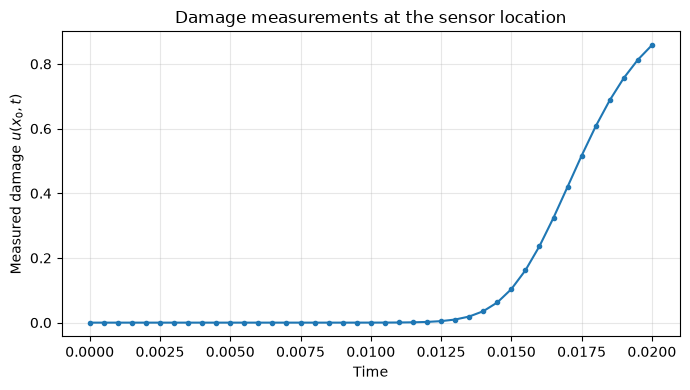

In [6]:
import matplotlib.pyplot as plt
import gdown

# Download only if the measurements are not already available
sensor_path = Path("damage_measurements.npy")

if not sensor_path.exists():
    gdown.download(
        id="16htWP91l5tpgK3ZYqjK-GHvVpW7lr2a5",
        output=str(sensor_path),
        quiet=False
    )

measurements = np.load(sensor_path).reshape(-1)

# FOM time step from the assignment
dt = 5e-4
sensor_times = np.arange(len(measurements)) * dt

print("Number of measurements:", len(measurements))
print("Time interval:", (sensor_times[0], sensor_times[-1]))
print("Damage range:", (measurements.min(), measurements.max()))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sensor_times, measurements, "o-", markersize=3)
ax.set(
    xlabel="Time",
    ylabel=r"Measured damage $u(x_0,t)$",
    title="Damage measurements at the sensor location"
)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. POD-NN Sensor Prediction

For any candidate parameter vector $\boldsymbol{\mu}$, the trained POD-NN predicts the reduced coefficients at all measurement times.

The predicted sensor signal is obtained by projecting these coefficients onto the precomputed POD observation vector:

$$
\widetilde{\mathbf m}(\boldsymbol{\mu})
=
A_{\mathrm{NN}}(\boldsymbol{\mu})\,\mathbf h_{x_0},
$$

where $A_{\mathrm{NN}}\in\mathbb{R}^{M\times N}$ contains the predicted POD coefficients at the $M=41$ measurement times, and $\mathbf h_{x_0}\in\mathbb{R}^{N}$ contains the POD basis functions evaluated at the sensor location.

This formulation requires only one batched neural network evaluation and a matrix-vector product for each candidate parameter vector, without reconstructing the full-order field.

Prediction shape: (41,)
Initial MSE: 0.081511


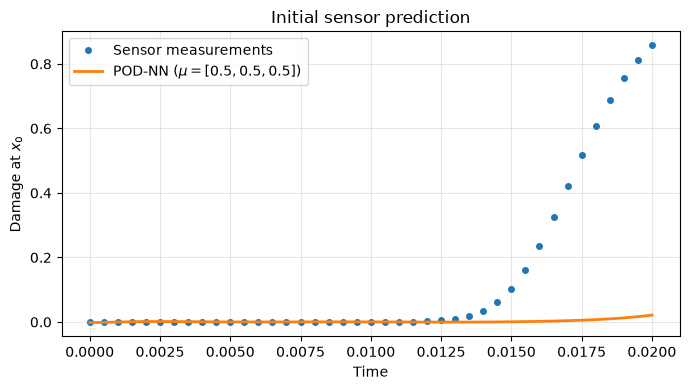

In [10]:
def predict_sensor(mu):
    """Predict the sensor time series for normalized parameters mu."""

    mu = np.asarray(mu, dtype=float).reshape(1, 3)

    # Build NN inputs for all measurement times
    X = sf.make_nn_inputs(mu, sensor_times)

    # Predict POD coefficients in their original scale
    A = sf.predict_coefficients(model, X, scaler)

    # Evaluate the predicted damage at the sensor location
    return (A @ sensor_modes.detach().cpu().numpy()).reshape(-1)


# Initial test at the center of the parameter domain
mu_initial = np.array([0.5, 0.5, 0.5])

prediction_initial = predict_sensor(mu_initial)

assert prediction_initial.shape == measurements.shape
assert np.all(np.isfinite(prediction_initial))

print("Prediction shape:", prediction_initial.shape)
print("Initial MSE:", np.mean((prediction_initial - measurements)**2))

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(sensor_times, measurements, "o",
        markersize=4, label="Sensor measurements")

ax.plot(sensor_times, prediction_initial, "-",
        linewidth=2, label=r"POD-NN ($\mu=[0.5,0.5,0.5]$)")

ax.set(
    xlabel="Time",
    ylabel=r"Damage at $x_0$",
    title="Initial sensor prediction"
)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Best candidates:
mu = [1.  0.5 0. ], MSE = 0.009408, final damage = 0.6429
mu = [0.  1.  0.5], MSE = 0.016307, final damage = 0.9742
mu = [1.  0.5 0.5], MSE = 0.019748, final damage = 0.4529
mu = [0. 1. 1.], MSE = 0.037815, final damage = 0.5085
mu = [1.  0.5 1. ], MSE = 0.059530, final damage = 0.1700


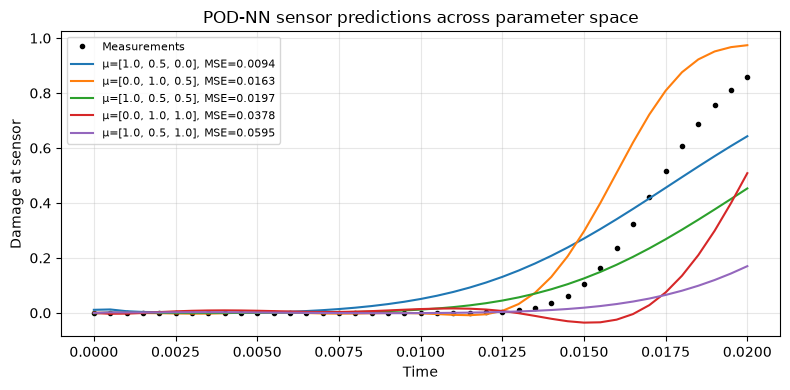

In [11]:
from itertools import product

# Explore a coarse grid in the normalized parameter domain
mu_values = [0.0, 0.5, 1.0]
candidates = np.array(list(product(mu_values, repeat=3)))

results = []

for mu in candidates:
    prediction = predict_sensor(mu)
    mse = np.mean((prediction - measurements)**2)
    results.append((mse, mu, prediction))

results.sort(key=lambda item: item[0])

print("Best candidates:")
for mse, mu, prediction in results[:5]:
    print(
        f"mu = {mu}, "
        f"MSE = {mse:.6f}, "
        f"final damage = {prediction[-1]:.4f}"
    )

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    sensor_times, measurements,
    "ko", markersize=3, label="Measurements"
)

for mse, mu, prediction in results[:5]:
    ax.plot(
        sensor_times, prediction,
        label=f"μ={mu.tolist()}, MSE={mse:.4f}"
    )

ax.set(
    xlabel="Time",
    ylabel="Damage at sensor",
    title="POD-NN sensor predictions across parameter space"
)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Parameter Identification

The unknown parameters are estimated by minimizing the mean squared discrepancy between the measured sensor signal and the POD-NN prediction:

$$
J(\boldsymbol{\mu})=
\frac{1}{M}\sum_{j=1}^{M}
\left[
\widetilde u(x_0,t_j;\boldsymbol{\mu})-m_j
\right]^2,
\qquad
\boldsymbol{\mu}\in[0,1]^3.
$$

The optimization is performed in the normalized parameter space, ensuring comparable parameter scales and allowing simple box constraints.

Since the nonlinear objective may contain multiple local minima, a multi-start strategy is adopted. The L-BFGS-B algorithm is initialized from different points in the admissible domain, and the solution with the lowest objective value is retained.

The neural network and POD basis remain fixed during optimization; only the physical parameters are varied.

In [ ]:
from scipy.optimize import minimize

# Objective function
def objective(mu):
    prediction = predict_sensor(mu)
    return float(np.mean((prediction - measurements)**2))


# Initial guesses: best grid candidates + random points
rng = np.random.default_rng(42)

grid_starts = np.array([item[1] for item in results[:5]])
random_starts = rng.uniform(0, 1, size=(10, 3))

initial_guesses = np.vstack([grid_starts, random_starts])

bounds = [(0.0, 1.0)] * 3

optimization_results = []

for i, mu0 in enumerate(initial_guesses):
    res = minimize(
        objective,
        x0=mu0,
        method="L-BFGS-B",
        bounds=bounds,
        options={
            "maxiter": 500,
            "ftol": 1e-12
        }
    )

    optimization_results.append(res)

    print(
        f"Start {i+1:02d}: "
        f"MSE={res.fun:.8f}, "
        f"mu={np.round(res.x, 4)}, "
        f"success={res.success}"
    )

# Select the best solution
best_result = min(optimization_results, key=lambda res: res.fun)

mu_opt = best_result.x
mse_opt = best_result.fun

# Convert normalized parameters to physical quantities
D_opt = 10 ** mu_opt[0]
r_opt = 10 ** (mu_opt[1] + 2)
delta_opt = mu_opt[2] + 1

print("\nOptimal parameters")
print(f"mu*   = {mu_opt}")
print(f"D     = {D_opt:.5f}")
print(f"r     = {r_opt:.5f}")
print(f"delta = {delta_opt:.5f}")
print(f"MSE   = {mse_opt:.8f}")

Start 01: MSE=0.91243256%, mu=[1.     0.5    0.0897], success=True
Start 02: MSE=1.63067393%, mu=[0.  1.  0.5], success=True
Start 03: MSE=1.97484866%, mu=[1.  0.5 0.5], success=True
Start 04: MSE=3.78150828%, mu=[0. 1. 1.], success=True
Start 05: MSE=5.95302135%, mu=[1.  0.5 1. ], success=True
Start 06: MSE=8.14675391%, mu=[0.774  0.4389 0.8586], success=True
Start 07: MSE=8.39821920%, mu=[0.6974 0.0942 0.9756], success=True
Start 08: MSE=0.13017590%, mu=[0.7611 0.7861 1.    ], success=True
Start 09: MSE=7.81509131%, mu=[1.     0.3708 1.    ], success=True
Start 10: MSE=5.96433431%, mu=[0.6439 0.8228 0.4434], success=True
Start 11: MSE=8.36271197%, mu=[0.2272 0.5546 0.0638], success=True
Start 12: MSE=2.10521538%, mu=[0.8276 0.6317 0.7581], success=True
Start 13: MSE=2.94848122%, mu=[0.3171 0.8683 0.8931], success=True
Start 14: MSE=8.14555287%, mu=[0.7784 0.1946 0.4667], success=True
Start 15: MSE=8.31704810%, mu=[0.7889 0.1543 0.683 ], success=True

Optimal parameters
mu*   = [0.761

In [22]:
optimization_results = []

for i, mu0 in enumerate(initial_guesses):
    res = minimize(
        objective,
        x0=mu0,
        method="L-BFGS-B",
        bounds=bounds,
        options={
            "maxiter": 500,
            "ftol": 1e-12,
            "gtol": 1e-7,
            "eps": 1e-4
        }
    )

    optimization_results.append(res)

    print(
        f"Start {i+1:02d}: "
        f"MSE={res.fun:.8f}, "
        f"mu={np.round(res.x, 4)}, "
        f"success={res.success}"
    )

best_result = min(optimization_results, key=lambda res: res.fun)

mu_opt = best_result.x
mse_opt = best_result.fun

D_opt = 10 ** mu_opt[0]
r_opt = 10 ** (mu_opt[1] + 2)
delta_opt = mu_opt[2] + 1

print("\nBest solution:")
print(f"mu* = {np.round(mu_opt, 6)}")
print(f"D = {D_opt:.5f}, r = {r_opt:.5f}, delta = {delta_opt:.5f}")
print(f"MSE = {mse_opt:.8f}")

Start 01: MSE=0.00004293, mu=[0.1301 0.8928 0.3274], success=True
Start 02: MSE=0.00003322, mu=[0.1897 0.9061 0.5348], success=True
Start 03: MSE=0.00000929, mu=[0.4088 0.891  0.882 ], success=True
Start 04: MSE=0.00000849, mu=[0.4078 0.892  0.8853], success=True
Start 05: MSE=0.00000746, mu=[0.4007 0.8947 0.8865], success=True
Start 06: MSE=0.00000633, mu=[0.4011 0.8974 0.9033], success=True
Start 07: MSE=0.00000710, mu=[0.407  0.8939 0.8957], success=True
Start 08: MSE=0.00003357, mu=[0.1856 0.9007 0.4972], success=True
Start 09: MSE=0.00001099, mu=[0.4271 0.8966 0.9568], success=True
Start 10: MSE=0.00003327, mu=[0.1565 0.9198 0.5464], success=True
Start 11: MSE=0.00004426, mu=[0.1257 0.8922 0.312 ], success=True
Start 12: MSE=0.00000763, mu=[0.4146 0.8927 0.9051], success=True
Start 13: MSE=0.00001043, mu=[0.4053 0.8907 0.8731], success=False
Start 14: MSE=0.00003168, mu=[0.1755 0.9065 0.5104], success=True
Start 15: MSE=0.00000774, mu=[0.411  0.8925 0.8956], success=True

Best sol

### Results and Discussion

The multi-start optimization identified the following normalized parameters:

$$
\boldsymbol{\mu}^{*}=(0.4011,\;0.8974,\;0.9033),
$$

corresponding to

$$
D^{*}=2.518,\qquad r^{*}=789.62,\qquad \delta^{*}=1.903.
$$

The optimized POD-NN prediction closely reproduces the sensor measurements, achieving a **relative L2 error of 0.8664%** and a normalized RMSE of 0.2932% (relative to the maximum measured damage). The maximum absolute discrepancy is less than 0.007, confirming the accuracy of the reconstructed temporal signal.

The multi-start results also reveal a non-convex objective landscape, with several initializations converging to different parameter combinations. Although many runs converge to a similar region, a low sensor reconstruction error does not necessarily guarantee unique identification of the true physical parameters.

Overall, the results demonstrate the effectiveness of the POD-NN as a computationally efficient surrogate for solving the inverse parameter identification problem, without requiring additional full-order simulations.

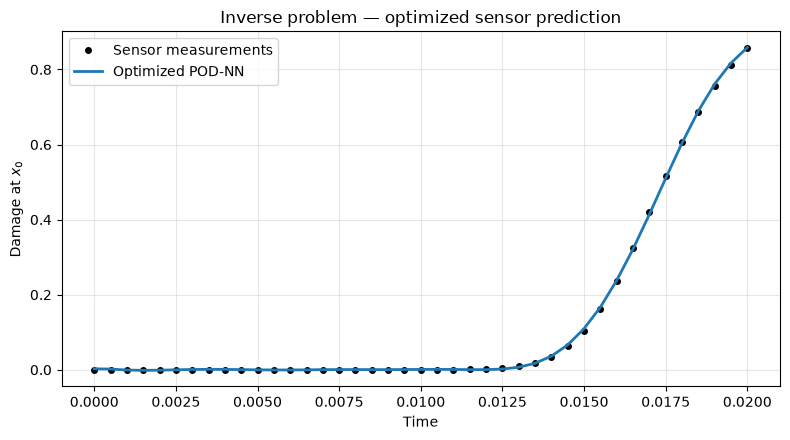

MSE:  0.00063300%
RMSE: 0.25159521%
Maximum absolute error: 0.60117841%


In [ ]:
prediction_opt = predict_sensor(mu_opt)
residuals = prediction_opt - measurements

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    sensor_times, measurements,
    "ko", markersize=4, label="Sensor measurements"
)
ax.plot(
    sensor_times, prediction_opt,
    "-", linewidth=2,
    label="Optimized POD-NN"
)

ax.set(
    xlabel="Time",
    ylabel=r"Damage at $x_0$",
    title="Inverse problem — optimized sensor prediction"
)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"MSE:  {np.mean(residuals**2):.8e}")
print(f"RMSE: {np.sqrt(np.mean(residuals**2)):.8e}")
print(f"Maximum absolute error: {np.max(np.abs(residuals)):.8e}")

In [23]:
residuals = prediction_opt - measurements

mse = np.mean(residuals**2)
rmse = np.sqrt(mse)

relative_l2 = (
    np.linalg.norm(residuals) /
    np.linalg.norm(measurements) * 100
)

nrmse = rmse / np.max(np.abs(measurements)) * 100

max_error_pct = (
    np.max(np.abs(residuals)) /
    np.max(np.abs(measurements)) * 100
)

print(f"MSE:                    {mse:.8e}")
print(f"RMSE:                   {rmse:.8e}")
print(f"Relative L2 error:      {relative_l2:.4f}%")
print(f"NRMSE (peak):           {nrmse:.4f}%")
print(f"Max error / peak:       {max_error_pct:.4f}%")

MSE:                    6.33001491e-06
RMSE:                   2.51595210e-03
Relative L2 error:      0.8664%
NRMSE (peak):           0.2932%
Max error / peak:       0.7007%


## 6. Spatial Reconstruction of the Identified Damage Evolution

Once the optimal parameters have been identified, the POD-NN can reconstruct the entire damage field over the U-bolt geometry.

Although parameter estimation relies only on measurements at a single sensor location, the surrogate provides a spatially distributed prediction:

$$
\widetilde{\mathbf u}(t;\boldsymbol{\mu}^{*})
=
V_N\mathbf a^{\mathrm{NN}}(t,\boldsymbol{\mu}^{*}).
$$

The reconstructed damage evolution is visualized to examine the propagation pattern associated with the identified parameters. This is a ROM-based spatial prediction, rather than an independently validated full-order reconstruction.

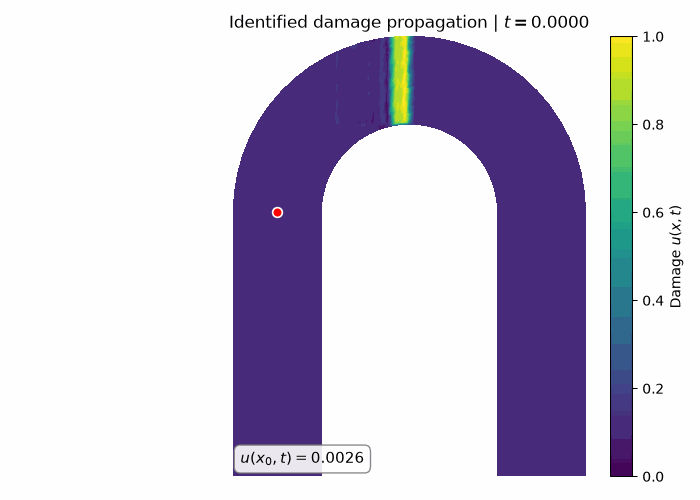

In [32]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from IPython.display import Image, display

# Sensor prediction for the identified parameters
sensor_opt = predict_sensor(mu_opt)

# Fixed contour levels, covering the full reconstructed range
# to avoid blank regions caused by out-of-range values
field_min = min(0.0, float(u_opt.min()))
field_max = max(1.0, float(u_opt.max()))
levels = np.linspace(field_min - 1e-6, field_max + 1e-6, 120)

# Shared color normalization: physical damage scale
norm = mpl.colors.Normalize(vmin=0.0, vmax=1.0)
cmap = plt.get_cmap("viridis")


def draw_damage_frame(i):
    fig, ax = plt.subplots(figsize=(7, 5))

    plt.sca(ax)

    fe.plot(
        u_opt[i],
        Vh,
        cmap="viridis",
        levels=levels
    )

    # Sensor location
    ax.plot(
        *x0,
        "ro",
        markersize=7,
        markeredgecolor="white",
        markeredgewidth=1.2
    )

    # Time and sensor value
    ax.set_title(
        rf"Identified damage propagation | $t={sensor_times[i]:.4f}$",
        fontsize=12
    )

    ax.text(
        0.02, 0.03,
        rf"$u(x_0,t)={sensor_opt[i]:.4f}$",
        transform=ax.transAxes,
        fontsize=11,
        bbox=dict(
            facecolor="white",
            alpha=0.9,
            edgecolor="gray",
            boxstyle="round,pad=0.4"
        )
    )

    # Fixed reference colorbar
    sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    cbar = fig.colorbar(sm, ax=ax, fraction=0.045, pad=0.04)
    cbar.set_label("Damage $u(x,t)$")

    ax.set_aspect("equal")
    plt.tight_layout()


gifs.save(
    draw_damage_frame,
    len(sensor_times),
    "identified_damage.gif"
)

display(Image(filename="identified_damage.gif"))

## 7. Spatial Ambiguity of the Inverse Problem

A low sensor reconstruction error does not necessarily guarantee unique parameter identification or accurate recovery of the entire spatial field.

To investigate this limitation, the best identified solution is compared with an alternative local solution obtained from a different optimization initialization.

Both parameter configurations produce relatively small discrepancies at the sensor, but correspond to different physical parameters. Their reconstructed damage fields are therefore compared at the final observation time $T=0.02$.

This comparison provides a qualitative assessment of the spatial ambiguity associated with single-point measurements.

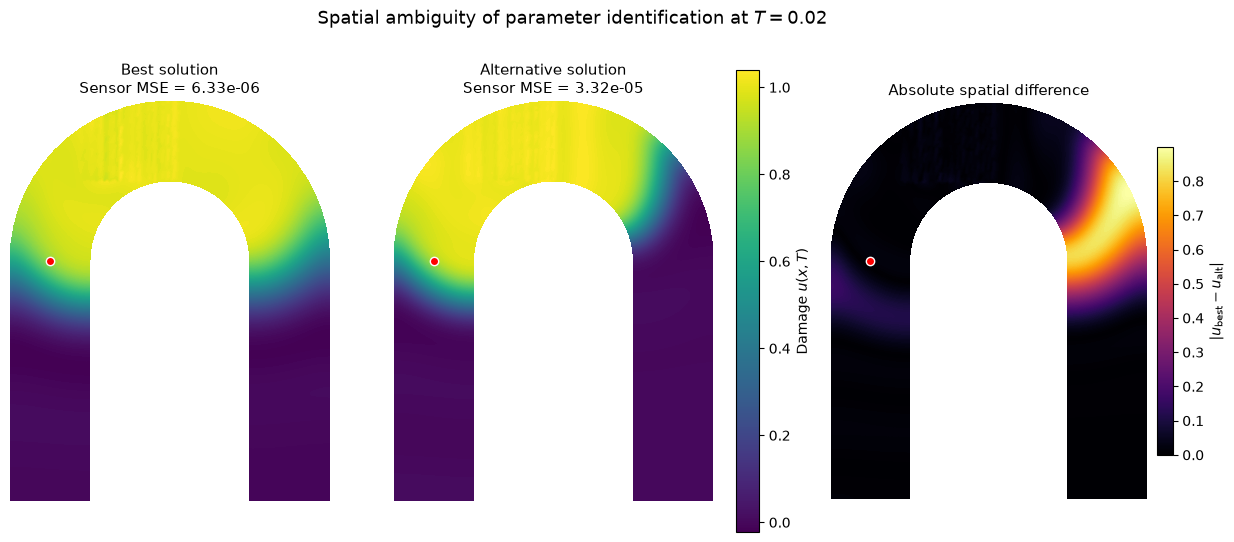

Best sensor MSE:        6.33001491e-06
Alternative sensor MSE: 3.32174204e-05
Maximum field difference: 0.8994


In [36]:
import matplotlib as mpl

# Alternative solution from the multi-start optimization
mu_alt = optimization_results[1].x

X_alt = sf.make_nn_inputs(mu_alt.reshape(1, -1), sensor_times)
A_alt = sf.predict_coefficients(model, X_alt, scaler)
u_alt = sf.reconstruct_pod(A_alt, Vn)

# Original reconstructed fields at final time
u_best_T = u_opt[-1]
u_alt_T = u_alt[-1]

# Difference computed on original (unclipped) fields
difference_T = np.abs(u_best_T - u_alt_T)

# Clip only the fields displayed in the first two panels
u_best_display = np.clip(u_best_T, 0.0, 1.0)
u_alt_display = np.clip(u_alt_T, 0.0, 1.0)

# Sensor fitting errors
mse_best = np.mean((predict_sensor(mu_opt) - measurements)**2)
mse_alt = np.mean((predict_sensor(mu_alt) - measurements)**2)

fig, axes = plt.subplots(1, 3, figsize=(15, 6))

fields = [
    u_best_T,
    u_alt_T,
    difference_T
]

titles = [
    f"Best solution\nSensor MSE = {mse_best:.2e}",
    f"Alternative solution\nSensor MSE = {mse_alt:.2e}",
    "Absolute spatial difference"
]

# Common normalization for damage fields
damage_norm = mpl.colors.Normalize(
    vmin=min(u_best_T.min(), u_alt_T.min()),
    vmax=max(u_best_T.max(), u_alt_T.max())
)

# Independent normalization for the difference
diff_norm = mpl.colors.Normalize(
    vmin=0,
    vmax=float(difference_T.max())
)

for i, (ax, field, title) in enumerate(zip(axes, fields, titles)):
    plt.sca(ax)

    # No vmin, vmax or levels passed to fe.plot
    fe.plot(
        field,
        Vh,
        cmap="viridis" if i < 2 else "inferno"
    )

    ax.plot(
        *x0,
        "ro",
        markersize=6,
        markeredgecolor="white",
        markeredgewidth=1
    )

    ax.set_title(title, fontsize=11)
    ax.set_aspect("equal")

# Colorbars
sm_damage = mpl.cm.ScalarMappable(
    norm=damage_norm,
    cmap="viridis"
)
sm_damage.set_array([])

cbar_damage = fig.colorbar(
    sm_damage,
    ax=axes[:2],
    fraction=0.035,
    pad=0.03
)
cbar_damage.set_label("Damage $u(x,T)$")

sm_diff = mpl.cm.ScalarMappable(
    norm=diff_norm,
    cmap="inferno"
)
sm_diff.set_array([])

cbar_diff = fig.colorbar(
    sm_diff,
    ax=axes[2],
    fraction=0.045,
    pad=0.03
)
cbar_diff.set_label(r"$|u_{\mathrm{best}}-u_{\mathrm{alt}}|$")

fig.suptitle(
    r"Spatial ambiguity of parameter identification at $T=0.02$",
    fontsize=13
)

plt.show()

print(f"Best sensor MSE:        {mse_best:.8e}")
print(f"Alternative sensor MSE: {mse_alt:.8e}")
print(f"Maximum field difference: {diff_max:.4f}")

### Discussion — Spatial Ambiguity

The spatial comparison reveals an important limitation of parameter identification based on a single sensor.

Although both identified parameter configurations reproduce the measured damage evolution with relatively small errors, their predicted spatial fields differ significantly, particularly along the right arm of the U-bolt.

The maximum pointwise discrepancy at $T=0.02$ is approximately $0.899$, indicating that locally similar sensor responses can correspond to substantially different damage propagation patterns elsewhere in the domain.

This highlights the distinction between **measurement fitting and spatial reconstruction accuracy**: minimizing the sensor residual does not guarantee unique identification of the physical parameters or accurate recovery of the full damage field.

Additional sensors at different spatial locations could improve parameter identifiability and reduce this ambiguity. However, without an independent full-order reference for the unknown parameter configuration, the spatial accuracy of the reconstructed field cannot be directly assessed.

In [37]:
np.savez(
    "artifacts/inverse_results.npz",
    mu_opt=mu_opt,
    D_opt=D_opt,
    r_opt=r_opt,
    delta_opt=delta_opt,
    sensor_times=sensor_times,
    measurements=measurements,
    prediction_opt=prediction_opt
)